# 🎯 Bird Species Classification — Training & Evaluation Module

> **Note:** This notebook loads `features.npz` (produced by `02_featureExtraction.ipynb`), trains Machine Learning classifiers, evaluates their accuracy, and saves the trained models to the `models/` directory.

---

## 📋 Overview

This notebook is **Step 3 of 3** in the project pipeline. We benchmark two distinct feature representations (**HOG** for shape and **LBP** for texture) across two popular machine learning algorithms (**Support Vector Machine** and **Random Forest**).

### Models Evaluated (4 Combinations)

| Model Name | Feature Type | Classifier | Kernel / Estimators |
|------------|--------------|------------|---------------------|
| **SVM (HOG)** | Shape (HOG) | Support Vector Classifier (`SVC`) | RBF Kernel ($C=10.0$) |
| **Random Forest (HOG)** | Shape (HOG) | `RandomForestClassifier` | 100 Trees |
| **SVM (LBP)** | Texture (LBP) | Support Vector Classifier (`SVC`) | RBF Kernel ($C=10.0$) |
| **Random Forest (LBP)** | Texture (LBP) | `RandomForestClassifier` | 100 Trees |

### Workflow Diagram

```
features.npz (X_hog, X_lbp, y)
              │
              ▼
  ┌───────────────────────┐
  │ Train / Test Split    │  ← 80% Training, 20% Testing (Stratified)
  └───────────┬───────────┘
              │
              ▼
  ┌───────────────────────┐
  │ StandardScaler        │  ← Normalize feature values to mean=0, std=1
  └───────────┬───────────┘
              │
              ▼
  ┌───────────────────────┐
  │ Fit & Evaluate Models │  ← Classification Report + Confusion Matrix
  └───────────┬───────────┘
              │
              ▼
     💾 Saved into 'models/'
     (svm_hog.pkl, rf_hog.pkl, svm_lbp.pkl, rf_lbp.pkl)
```





---
## ⚙️ Step 1 — Install Dependencies

Ensures base vision and machine learning packages are available.

In [1]:
!pip install ultralytics
!pip install opencv-python

---
## 📦 Step 2 — Import Machine Learning Libraries


In [3]:
import os
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

---
## 📁 Step 3 — Locate Feature File & Output Directory

Locates `features.npz` (searching current and parent directory) and sets the `models/` directory where trained weights will be saved.

In [4]:
features_path = "features.npz" if os.path.exists("features.npz") else "../features.npz"
models_dir = "models" if os.path.exists("models") else "../models"

---
## 🚀 Step 4 — Train, Benchmark, and Save Models (`train_and_eval`)

### What happens in this step:
1. **Load Data:** Reads `X_hog`, `X_lbp`, and labels `y` from `features.npz`.
2. **Split Data:** Performs stratified 80/20 train/test split on both feature sets.
3. **Standardization:** Fits and saves `StandardScaler` for both HOG and LBP.
4. **Benchmarking:** Trains 4 distinct models:
   - SVM (HOG) & Random Forest (HOG)
   - SVM (LBP) & Random Forest (LBP)
5. **Evaluation:** Prints Precision, Recall, F1-Score, and plots Confusion Matrices.
6. **Export:** Saves all 4 trained `.pkl` models and scalers into the `models/` folder.


 Training and Evaluating: SVM (HOG)
                    precision    recall  f1-score   support

AMERICAN GOLDFINCH       0.63      0.66      0.64        29
          BARN OWL       0.70      0.54      0.61        26
 CARMINE BEE-EATER       0.65      0.65      0.65        26
  DOWNY WOODPECKER       0.56      0.64      0.60        28
   EMPEROR PENGUIN       0.83      0.86      0.84        28
          FLAMINGO       0.65      0.65      0.65        26

          accuracy                           0.67       163
         macro avg       0.67      0.67      0.67       163
      weighted avg       0.67      0.67      0.67       163



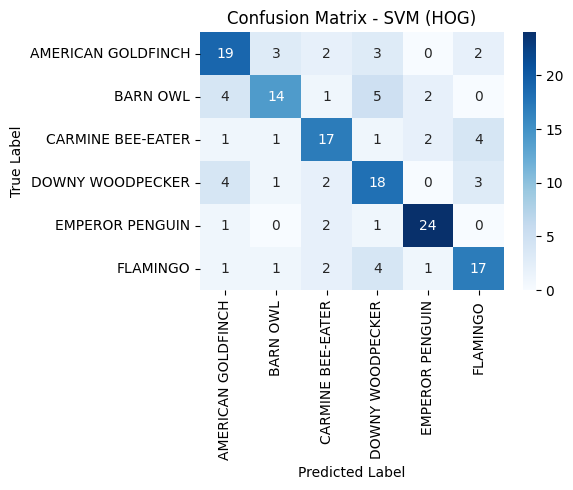

Saved trained model to '../models\svm_hog.pkl'

 Training and Evaluating: Random Forest (HOG)
                    precision    recall  f1-score   support

AMERICAN GOLDFINCH       0.57      0.59      0.58        29
          BARN OWL       0.52      0.46      0.49        26
 CARMINE BEE-EATER       0.55      0.62      0.58        26
  DOWNY WOODPECKER       0.42      0.50      0.46        28
   EMPEROR PENGUIN       0.69      0.71      0.70        28
          FLAMINGO       0.53      0.38      0.44        26

          accuracy                           0.55       163
         macro avg       0.55      0.54      0.54       163
      weighted avg       0.55      0.55      0.54       163



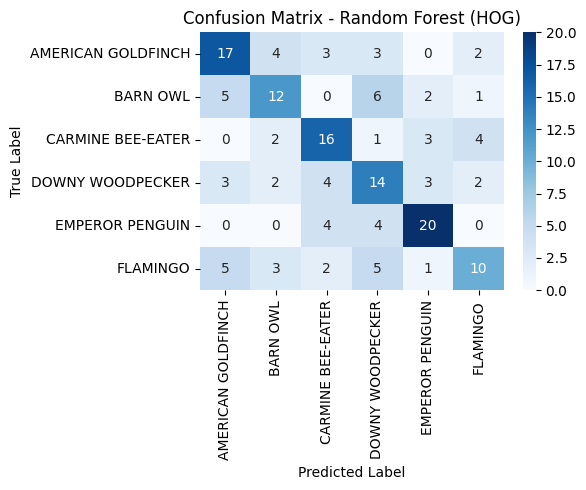

Saved trained model to '../models\rf_hog.pkl'

 Training and Evaluating: SVM (LBP)
                    precision    recall  f1-score   support

AMERICAN GOLDFINCH       0.67      0.69      0.68        29
          BARN OWL       0.61      0.54      0.57        26
 CARMINE BEE-EATER       0.51      0.69      0.59        26
  DOWNY WOODPECKER       0.83      0.68      0.75        28
   EMPEROR PENGUIN       0.83      0.86      0.84        28
          FLAMINGO       0.87      0.77      0.82        26

          accuracy                           0.71       163
         macro avg       0.72      0.70      0.71       163
      weighted avg       0.72      0.71      0.71       163



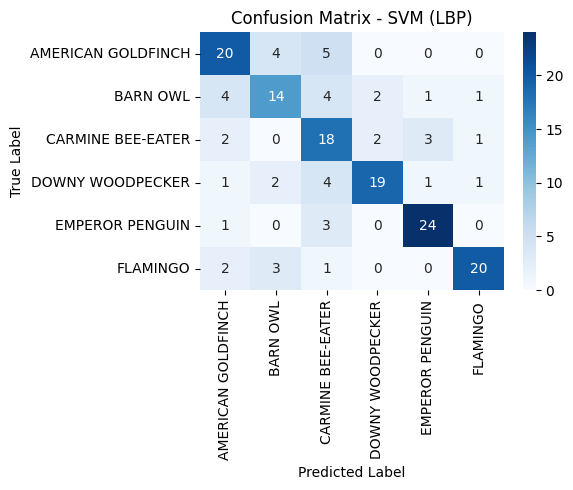

Saved trained model to '../models\svm_lbp.pkl'

 Training and Evaluating: Random Forest (LBP)
                    precision    recall  f1-score   support

AMERICAN GOLDFINCH       0.50      0.55      0.52        29
          BARN OWL       0.55      0.42      0.48        26
 CARMINE BEE-EATER       0.48      0.58      0.53        26
  DOWNY WOODPECKER       0.74      0.71      0.73        28
   EMPEROR PENGUIN       0.71      0.86      0.77        28
          FLAMINGO       0.63      0.46      0.53        26

          accuracy                           0.60       163
         macro avg       0.60      0.60      0.59       163
      weighted avg       0.60      0.60      0.60       163



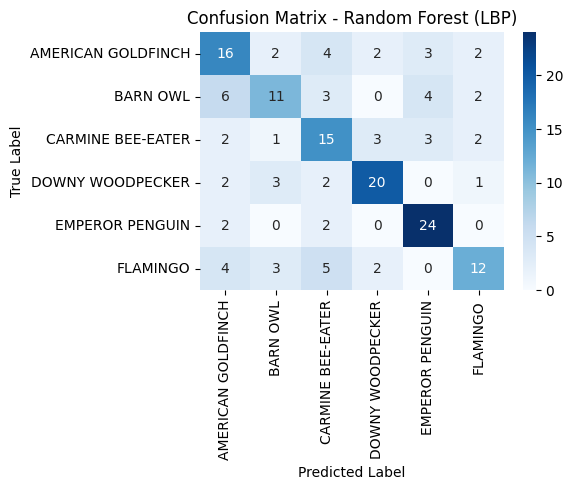

Saved trained model to '../models\rf_lbp.pkl'


In [5]:
def train_and_eval():
    os.makedirs(models_dir, exist_ok=True)


    if not os.path.exists(features_path):
        raise FileNotFoundError(f"Could not find '{features_path}'. Run feature extraction first!")

    data = np.load(features_path, allow_pickle=True)
    X_hog = data["X_hog"]
    X_lbp = data["X_lbp"]
    y = data["y"]
    label_map = data["label_map"].item()
    target_names = [label_map[i] for i in sorted(label_map.keys())]


    X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
        X_hog, y, test_size=0.20, random_state=42, stratify=y
    )

    X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
        X_lbp, y, test_size=0.20, random_state=42, stratify=y
    )


    scaler_hog = StandardScaler()
    X_train_h = scaler_hog.fit_transform(X_train_h)
    X_test_h = scaler_hog.transform(X_test_h)

    scaler_lbp = StandardScaler()
    X_train_l = scaler_lbp.fit_transform(X_train_l)
    X_test_l = scaler_lbp.transform(X_test_l)


    joblib.dump(scaler_hog, os.path.join(models_dir, "scaler_hog.pkl"))
    joblib.dump(scaler_lbp, os.path.join(models_dir, "scaler_lbp.pkl"))


    models_to_evaluate = [
        ("SVM (HOG)", SVC(kernel='rbf', C=10.0, probability=True, random_state=42), X_train_h, X_test_h, y_train_h, y_test_h, "svm_hog.pkl"),
        ("Random Forest (HOG)", RandomForestClassifier(n_estimators=100, random_state=42), X_train_h, X_test_h, y_train_h, y_test_h, "rf_hog.pkl"),
        ("SVM (LBP)", SVC(kernel='rbf', C=10.0, probability=True, random_state=42), X_train_l, X_test_l, y_train_l, y_test_l, "svm_lbp.pkl"),
        ("Random Forest (LBP)", RandomForestClassifier(n_estimators=100, random_state=42), X_train_l, X_test_l, y_train_l, y_test_l, "rf_lbp.pkl"),
    ]

    for name, model, X_tr, X_te, y_tr, y_te, save_filename in models_to_evaluate:
        print(f"\n==========================================")
        print(f" Training and Evaluating: {name}")
        print(f"==========================================")

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)

        print(classification_report(y_te, y_pred, target_names=target_names, zero_division=0))


        cm = confusion_matrix(y_te, y_pred)
        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=target_names, yticklabels=target_names)
        plt.title(f"Confusion Matrix - {name}")
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.tight_layout()
        plt.show()


        save_path = os.path.join(models_dir, save_filename)
        joblib.dump(model, save_path)
        print(f"Saved trained model to '{save_path}'")

if __name__ == "__main__":
    train_and_eval()